# Metadata checks: uncertainty, cutoffs and calibration

This notebook examines the main weaknesses in the metadata comparisons and prepare one fixed model for later final testing.

Is there clear evidence that the network improves on the spline, how accurate are the spline's risk estimates, and what happens when a cutoff aims to find 80% of malignant images?

[04_metadata_tuning_d1.ipynb](04_metadata_tuning_d1.ipynb) retains the fixed spline after checking setting searches. This notebook keeps that choice, reads the three network runs saved by notebook 03b and checks model differences, probability calibration and cutoff decisions with patient separation.

The saved spline AP is 0.0484 and the three-network average is 0.0465. Their uncertainty interval gives no clear evidence of an AP improvement from the network. A cutoff selected to aim for 80% recall in training finds 79.7% of malignant images in held-out patients while flagging 67.0% of all images. The reserved test labels are not used in this experiment.


## Context and methods

### Why add these checks?

| Step | Why it matters | What we do |
|---|---|---|
| Validate the original values | Converting 1.5 to an integer could silently turn it into label 1 | Reject invalid labels before conversion; check unique images and patient folds |
| Fit preprocessing inside training | A validation patient's age should not change the training median or age curve | Fit the complete spline pipeline separately in every training partition |
| Choose cutoffs within training | A cutoff chosen from the cases used to report its performance can look too favourable | Choose it using inner held-out scores, then assess it on outer patients |
| Check calibration | A predicted risk of 3% should roughly match 3% malignancy among comparable cases | Compare the raw scores with a fixed logistic adjustment fitted on training scores |
| Resample whole patients | Several images from one person are related | Draw patients with replacement, keeping all their images and comparing models on the same draw |
| Read all three network runs | One favourable starting point or stopping split can produce a lucky result | Use the three runs declared in notebook 03b and their equal average |
| Check age, sex and site groups | An overall score can hide weaknesses in particular groups | Report case counts and held-out results under one common cutoff policy |
| Freeze the method | Changes after seeing final-test results would turn the test into another development set | Save the model, cutoff, training identities and source fingerprints before testing |

### Keep selection and assessment separate

For each of the five outer folds:

1. Set aside that fold's patients for assessment.
2. Within the four training folds, fit on three and predict the fourth, four times. This gives inner out-of-fold (OOF) scores: predictions for training patients made without training on them.
3. Use those inner scores to adjust the probabilities and choose cutoffs.
4. Fit the spline on all four training folds and predict the outer patients.
5. Combine the five outer prediction tables and calculate performance.

The adjustment, called recalibration, learns two coefficients to change the level and spread of the probabilities. Its regularisation setting stays fixed; we do not search for whichever calibration method looks best. The outer folds assess the whole procedure, including cutoff selection.

### What the measures mean

Average precision (AP) is the main ranking measure. Larger values mean malignant images are concentrated nearer the top of the ranking. ROC-AUC describes how often a malignant image scores above a benign image; 0.5 indicates chance-level ranking. Log loss and Brier score measure probability error, so smaller is better.

We measure results per image, while patients are the unit used for splitting and resampling. A patient with many images contributes more lesions to a score. This is therefore an image-level prediction task, not a patient-level diagnosis model.

The cutoff scenario aims for 80% recall on inner training scores, choosing the highest cutoff that meets it. Recall is the fraction of malignant images flagged. The 80% target is an academic scenario, not a clinical requirement, and recall in outer patients may be lower.

The 95% bootstrap intervals resample patients from the saved predictions. They describe uncertainty in those results without retraining the models. They cannot correct earlier model selection or establish performance at new hospitals. The three network runs change both the random seed and stopping fold, so their spread reflects both choices together.

The age bands under 50 and 50 or older are fixed reporting groups. We suppress performance intervals for groups with fewer than ten patients who have a malignant image. That caution does not guarantee that larger groups are reliable. A patient's images can appear in several age or site groups, so their patient counts should not be added together.

Method references: [patient-grouped cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data) and [probability calibration](https://scikit-learn.org/stable/modules/calibration.html).


### 1. Set up the run

Run notebook 03b first to create its three network prediction files. Use the dependencies recorded in `requirements-metadata.txt` and the project Python kernel. This notebook records fingerprints of the input files and executable code so it can check that later comparisons use the same experiment.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import sys

import joblib
import nbformat
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.metadata_model import (
    FEATURES, SPECIFICATION, evaluate_outer_fold, file_sha256, fit_final_bundle,
)
from melanoma_detection.metadata_evaluation import (
    calibration_bins, decision_metrics, patient_bootstrap, probability_metrics, validate_probabilities,
)
from melanoma_detection.metadata_validation import validate_metadata_frame

DATA_PATH = PROJECT_ROOT / "data/subset/processed/train_folds.csv"
NN_PATH = PROJECT_ROOT / "results/predictions/metadata_nn_oof_d1.csv"
NN_CONFIG_PATH = PROJECT_ROOT / "results/metrics/metadata_nn_run_config_d1.json"
OUTPUT_ROOT = PROJECT_ROOT / "results"
FIGURES = OUTPUT_ROOT / "figures"
TABLES = OUTPUT_ROOT / "tables"
METRICS = OUTPUT_ROOT / "metrics"
PREDICTIONS = OUTPUT_ROOT / "predictions"
MODEL_DIR = PROJECT_ROOT / "models/metadata_d1"
for path in [FIGURES, TABLES, METRICS, PREDICTIONS, MODEL_DIR]:
    path.mkdir(parents=True, exist_ok=True)
TARGET_RECALL = 0.80
BOOTSTRAP_REPETITIONS = 2000
BOOTSTRAP_SEED = 42
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
INPUT_HASH = file_sha256(DATA_PATH)
print("Only development data:", DATA_PATH.relative_to(PROJECT_ROOT))
print("Input SHA256:", INPUT_HASH)

Only development data: data\subset\processed\train_folds.csv
Input SHA256: 4020a29a53b96943443e4d6173d35dabc6954fd5bd7d4d9db73a6b554a86a324


## Data

### 2. Check the inputs and match images

Match saved predictions by image name, then check patient IDs, labels and folds. The network input and code fingerprints must also match. These checks stop the notebook if a prediction file comes from another dataset or an older method. The table below confirms the development image and patient counts.


In [2]:
train = validate_metadata_frame(pd.read_csv(DATA_PATH, dtype={"age_approx": "string", "target": "string"}))
nn_config = json.loads(NN_CONFIG_PATH.read_text(encoding="utf-8"))
if nn_config["input_sha256"] != INPUT_HASH:
    raise ValueError("NN predictions are stale. Rerun notebook 03b on these exact folds.")
if nn_config["prediction_sha256"] != file_sha256(NN_PATH):
    raise ValueError("NN predictions differ from their saved run configuration.")
nn_notebook = nbformat.read(PROJECT_ROOT / "notebooks/03b_metadata_neural_network_d1.ipynb", as_version=4)
nn_code_hash = hashlib.sha256("\n\n".join(cell.source for cell in nn_notebook.cells if cell.cell_type == "code").encode("utf-8")).hexdigest()
if nn_config["code_sha256"] != nn_code_hash:
    raise ValueError("NN code changed after its saved run. Rerun notebook 03b.")
if nn_config["validation_source_sha256"] != file_sha256(PROJECT_ROOT / nn_config["validation_source_path"]):
    raise ValueError("NN validation source changed after its saved run.")
nn_predictions = pd.read_csv(NN_PATH)
if nn_predictions.image_name.duplicated().any() or set(nn_predictions.image_name) != set(train.image_name):
    raise ValueError("NN predictions do not cover each development image exactly once.")
nn_predictions = nn_predictions.set_index("image_name").loc[train.image_name].reset_index()
for column in ["patient_id", "target", "fold"]:
    if not np.array_equal(train[column].to_numpy(), nn_predictions[column].to_numpy()):
        raise ValueError(f"NN identity mismatch: {column}")
display(pd.DataFrame([{
    "Images": len(train), "Patients": train.patient_id.nunique(),
    "Malignant images": int(train.target.sum()),
    "Patients with malignancy": int(train.groupby("patient_id").target.max().sum()),
    "Malignant image fraction": train.target.mean(),
}]).round(4))

,Images,Patients,Malignant images,Patients with malignancy,Malignant image fraction
0,6864,422,128,88,0.0186


## Results

### 3. Select calibration and cutoffs using training patients

The raw spline keeps four cubic age knots and regularisation C=1. For every outer fold, only the inner training scores supply information for recalibration and cutoff selection. The saved audit table records the size and class counts of each partition.

The table below shows each training-selected cutoff beside its results on outer patients. Compare sensitivity (malignant images found), specificity (benign images left unflagged), precision (malignancy among flagged images) and the fraction flagged. These columns show why meeting a recall target can require many false alarms.


In [3]:
outer_parts, audit_parts = [], []
for fold in range(5):
    predictions, split_audit = evaluate_outer_fold(train, fold, target_recall=TARGET_RECALL)
    outer_parts.append(predictions)
    audit_parts.append(split_audit)
outer_predictions = pd.concat(outer_parts, ignore_index=True).set_index("image_name").loc[train.image_name].reset_index()
split_audit = pd.concat(audit_parts, ignore_index=True)
if not split_audit.patient_overlap.eq(0).all():
    raise ValueError("Patient overlap found.")
np.testing.assert_allclose(outer_predictions.p_spline_raw, nn_predictions.p_spline, atol=1e-10, rtol=1e-9)
for column in ["p_spline_raw", "p_spline_calibrated"]:
    validate_probabilities(train.target, outer_predictions[column])
for column in ["p_nn_seed_42", "p_nn_seed_142", "p_nn_seed_242", "p_nn_mean"]:
    validate_probabilities(train.target, nn_predictions[column])
np.testing.assert_allclose(nn_predictions.p_nn_mean, nn_predictions[["p_nn_seed_42", "p_nn_seed_142", "p_nn_seed_242"]].mean(axis=1), atol=1e-12)
outer_predictions.to_csv(PREDICTIONS / "metadata_robustness_oof_d1.csv", index=False)
split_audit.to_csv(TABLES / "metadata_robustness_split_audit_d1.csv", index=False)

fold_rows = []
for fold, rows in outer_predictions.groupby("fold"):
    for version, p_column, decision_column, threshold_column in [
        ("Raw spline", "p_spline_raw", "decision_raw", "raw_threshold"),
        ("Recalibrated spline", "p_spline_calibrated", "decision_calibrated", "calibrated_threshold"),
    ]:
        fold_rows.append({"fold": fold, "procedure": version, "training_selected_threshold": rows[threshold_column].iloc[0],
                          **probability_metrics(rows.target, rows[p_column]), **decision_metrics(rows.target, rows[decision_column])})
fold_metrics = pd.DataFrame(fold_rows)
fold_metrics.to_csv(METRICS / "metadata_robustness_fold_metrics_d1.csv", index=False)
display(fold_metrics[["fold", "procedure", "training_selected_threshold", "sensitivity", "specificity", "precision", "flagged_fraction"]].round(4))

,fold,procedure,training_selected_threshold,sensitivity,specificity,precision,flagged_fraction
0,0,Raw spline,0.0103,1.0000,0.1822,0.0222,0.8212
1,0,Recalibrated spline,0.0131,1.0000,0.1822,0.0222,0.8212
2,1,Raw spline,0.0115,0.6538,0.4042,0.0208,0.5969
3,1,Recalibrated spline,0.0130,0.6538,0.4042,0.0208,0.5969
4,2,Raw spline,0.0095,0.8077,0.4007,0.0252,0.6032
5,2,Recalibrated spline,0.0113,0.8077,0.4007,0.0252,0.6032
6,3,Raw spline,0.0102,0.8400,0.2125,0.0194,0.7885
7,3,Recalibrated spline,0.0118,0.8400,0.2125,0.0194,0.7885
8,4,Raw spline,0.0112,0.6923,0.4621,0.0243,0.5409
9,4,Recalibrated spline,0.0130,0.6923,0.4621,0.0243,0.5409


### 4. Compare models with patient-based uncertainty intervals

For each of 2,000 repetitions, we draw 422 patients with replacement and keep all their images. A patient drawn twice contributes their images twice. We calculate all model scores on the same draw, then subtract the spline score. This paired comparison keeps the patient sample the same for both methods.

The table reports the middle 95% of these resampled scores. In the left chart, the horizontal axis is AP and the rows are models. Blue dots are the observed scores and blue horizontal lines are their 95% intervals. Farther right is better, but compare the paired chart before deciding that one model improves on another.

In the right chart, the horizontal axis is network AP minus spline AP. Gold squares show the observed difference and gold lines show its 95% interval. The dashed vertical line at zero means no change. An interval extending to both sides of zero gives no clear direction for the difference. The network mean's interval runs from -0.0190 to +0.0059, so these predictions do not clearly favour an AP improvement.

These figures show how uncertain the comparison is. The intervals reuse saved predictions, without refitting models, and are exploratory; they are not adjusted for the several comparisons.


,model_name,reference_model,metric,estimate,ci_lower,ci_upper,n_valid
0,Raw spline,NaN,average_precision,0.0484,0.0325,0.0813,2000
1,Raw spline,NaN,roc_auc,0.6499,0.5752,0.7221,2000
4,Recalibrated spline,NaN,average_precision,0.0478,0.0327,0.0783,2000
5,Recalibrated spline,NaN,roc_auc,0.6460,0.5726,0.7186,2000
8,NN seed 42,NaN,average_precision,0.0458,0.0323,0.0707,2000
9,NN seed 42,NaN,roc_auc,0.6627,0.5933,0.7285,2000
12,NN seed 142,NaN,average_precision,0.0486,0.0335,0.0733,2000
13,NN seed 142,NaN,roc_auc,0.6743,0.6076,0.7378,2000
16,NN seed 242,NaN,average_precision,0.0461,0.0329,0.0711,2000
17,NN seed 242,NaN,roc_auc,0.6746,0.6075,0.7372,2000


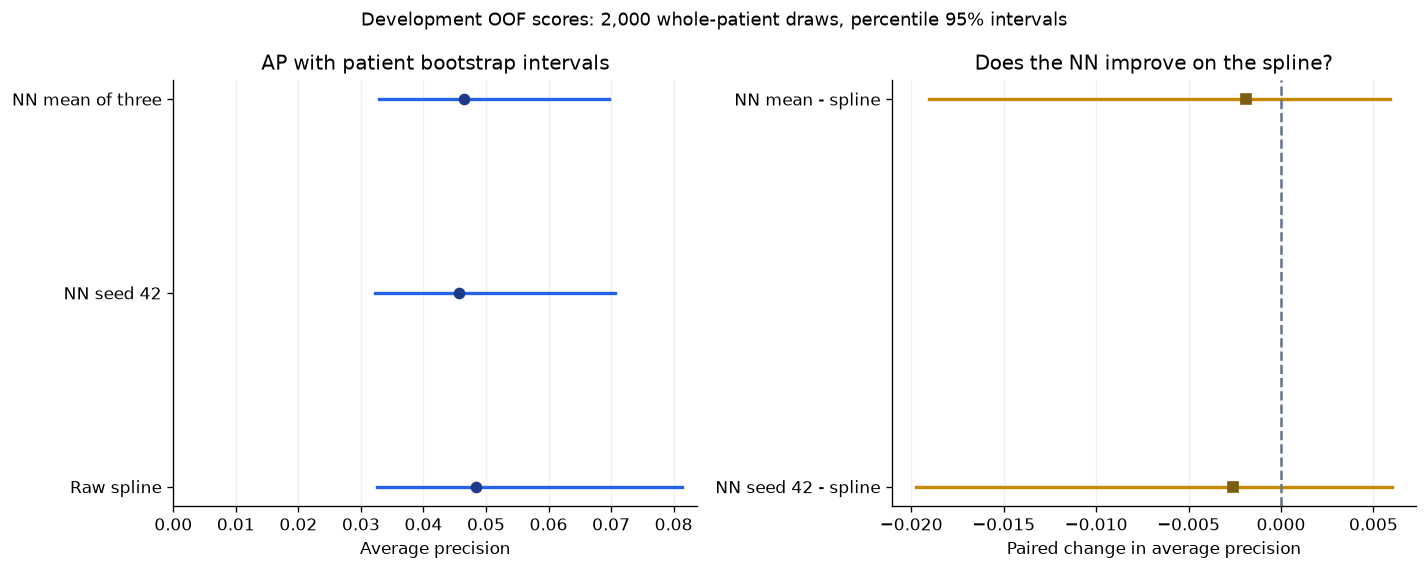

In [4]:
probability_sets = {
    "Raw spline": outer_predictions.p_spline_raw.to_numpy(),
    "Recalibrated spline": outer_predictions.p_spline_calibrated.to_numpy(),
    "NN seed 42": nn_predictions.p_nn_seed_42.to_numpy(),
    "NN seed 142": nn_predictions.p_nn_seed_142.to_numpy(),
    "NN seed 242": nn_predictions.p_nn_seed_242.to_numpy(),
    "NN mean of three": nn_predictions.p_nn_mean.to_numpy(),
}
intervals = patient_bootstrap(
    train.target, train.patient_id, probability_sets,
    n_bootstrap=BOOTSTRAP_REPETITIONS, seed=BOOTSTRAP_SEED,
    comparisons=[("Recalibrated spline", "Raw spline"), ("NN seed 42", "Raw spline"), ("NN mean of three", "Raw spline")],
)
intervals.to_csv(METRICS / "metadata_patient_bootstrap_d1.csv", index=False)
display(intervals.loc[intervals.metric.isin(["average_precision", "roc_auc"]),
                      ["model_name", "reference_model", "metric", "estimate", "ci_lower", "ci_upper", "n_valid"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
selected = ["Raw spline", "NN seed 42", "NN mean of three"]
for index, name in enumerate(selected):
    row = intervals[(intervals.model_name == name) & intervals.reference_model.isna() & (intervals.metric == "average_precision")].iloc[0]
    axes[0].plot([row.ci_lower, row.ci_upper], [index, index], color="#2563EB", linewidth=2)
    axes[0].plot(row.estimate, index, "o", color="#1E3A8A")
axes[0].set_yticks(range(len(selected)), selected)
axes[0].set_xlim(left=0)
axes[0].set_xlabel("Average precision")
axes[0].set_title("AP with patient bootstrap intervals")
for index, name in enumerate(["NN seed 42", "NN mean of three"]):
    row = intervals[(intervals.model_name == name) & (intervals.reference_model == "Raw spline") & (intervals.metric == "average_precision")].iloc[0]
    axes[1].plot([row.ci_lower, row.ci_upper], [index, index], color="#C58A00", linewidth=2)
    axes[1].plot(row.estimate, index, "s", color="#7C5E10")
axes[1].axvline(0, color="#64748B", linestyle="--")
axes[1].set_yticks([0, 1], ["NN seed 42 - spline", "NN mean - spline"])
axes[1].set_xlabel("Paired change in average precision")
axes[1].set_title("Does the NN improve on the spline?")
for axis in axes: axis.grid(axis="x", alpha=0.2)
fig.suptitle("Development OOF scores: 2,000 whole-patient draws, percentile 95% intervals", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "metadata_patient_bootstrap_d1.png", dpi=180, bbox_inches="tight")
plt.show()

### 5. Read the calibration and score-distribution plots

Calibration asks whether predicted risks agree with observed rates. We put scores into five roughly equal-sized groups without splitting identical scores. Blue circles represent the raw spline and gold squares represent its training-only recalibrated version.

In the left panel, the horizontal axis is the group's average predicted probability and the vertical axis is its observed malignant-image fraction. A point near the grey dashed diagonal indicates agreement. A point above it means the model predicted too little risk for that group; a point below it means it predicted too much. The vertical lines are 95% intervals for the observed rate, calculated by resampling whole patients with the score groups held fixed. They do not show uncertainty in the horizontal position.

In the right panel, the horizontal axis is predicted probability and the vertical axis is the image count. Blue and gold outlines show where each method places its scores. This explains whether recalibration compresses or spreads the risk estimates; most scores are small because malignant images are rare.

Read the plots beside the bin counts and error scores. Few malignant cases make a calibration curve noisy, and Brier score or log loss alone does not isolate calibration from ranking. Recalibration changes the scores but is not automatically an improvement.


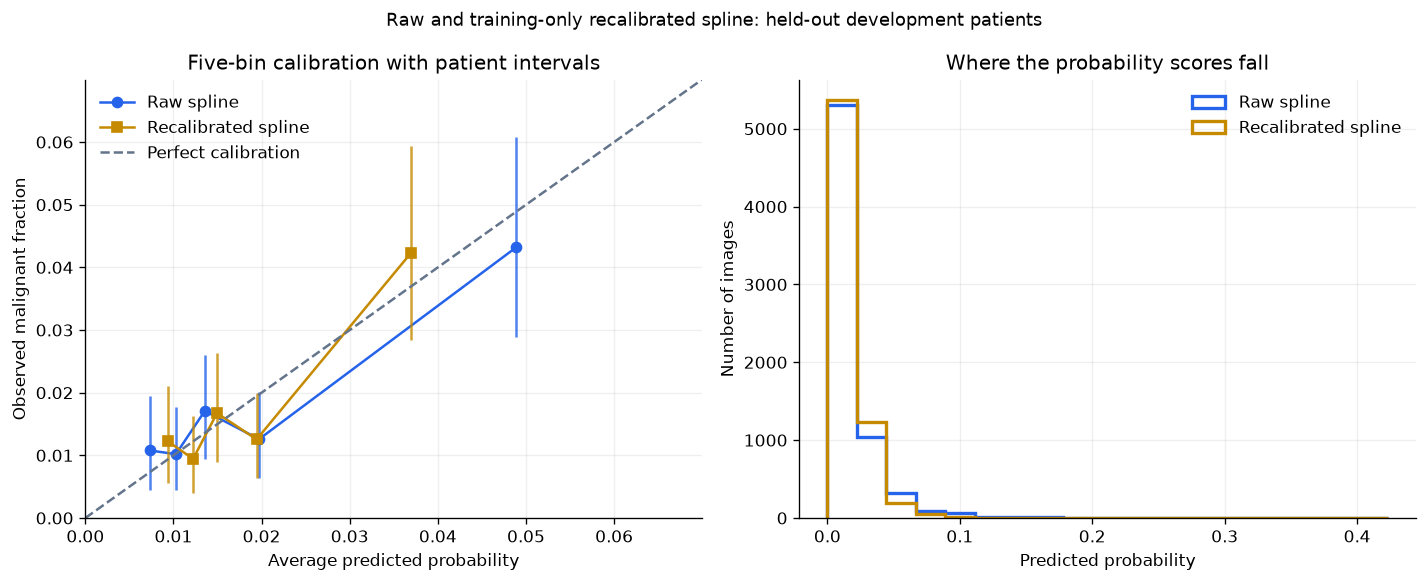

,model,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,observed_lower,observed_upper
0,Raw spline,1,1391,15,0.0073,0.0108,0.0026,0.0089,120,0.0044,0.0194
1,Raw spline,2,1374,14,0.0103,0.0102,0.0090,0.0115,157,0.0045,0.0177
2,Raw spline,3,1405,24,0.0136,0.0171,0.0116,0.0160,201,0.0094,0.0260
3,Raw spline,4,1351,17,0.0197,0.0126,0.0161,0.0259,204,0.0064,0.0201
4,Raw spline,5,1343,58,0.0489,0.0432,0.0261,0.4223,195,0.0289,0.0608
5,Recalibrated spline,1,1384,17,0.0093,0.0123,0.0040,0.0109,118,0.0055,0.0210
6,Recalibrated spline,2,1378,13,0.0122,0.0094,0.0109,0.0134,167,0.0040,0.0162
7,Recalibrated spline,3,1374,23,0.0149,0.0167,0.0134,0.0168,179,0.0090,0.0264
8,Recalibrated spline,4,1355,17,0.0194,0.0125,0.0169,0.0239,215,0.0064,0.0199
9,Recalibrated spline,5,1373,58,0.0369,0.0422,0.0239,0.2522,196,0.0284,0.0593


,procedure,average_precision,roc_auc,log_loss,brier
0,Raw spline,0.04837,0.64986,0.08974,0.01814
1,Recalibrated spline,0.04779,0.64597,0.08955,0.01812


In [5]:
def bin_rate_intervals(frame, probabilities, bins, repetitions=2000):
    rng = np.random.default_rng(42)
    groups, codes = np.unique(frame.patient_id.to_numpy(), return_inverse=True)
    draws = rng.multinomial(len(groups), np.full(len(groups), 1 / len(groups)), size=repetitions)
    records = []
    for row in bins.itertuples():
        inside = (probabilities >= row.min_probability) & (probabilities <= row.max_probability)
        totals = np.bincount(codes, weights=inside.astype(float), minlength=len(groups))
        positives = np.bincount(codes, weights=inside * frame.target.to_numpy(), minlength=len(groups))
        denominators = draws @ totals
        rates = np.divide(draws @ positives, denominators, out=np.full(repetitions, np.nan), where=denominators > 0)
        finite = rates[np.isfinite(rates)]
        lower, upper = np.quantile(finite, [0.025, 0.975])
        records.append({"bin": row.bin, "observed_lower": lower, "observed_upper": upper})
    return pd.DataFrame(records)

calibration_tables = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.9))
for name, color, marker in [("Raw spline", "#2563EB", "o"), ("Recalibrated spline", "#C58A00", "s")]:
    probabilities = probability_sets[name]
    bins = calibration_bins(train.target, probabilities, n_bins=5, groups=train.patient_id)
    bins = bins.merge(bin_rate_intervals(train, probabilities, bins), on="bin", validate="one_to_one")
    bins.insert(0, "model", name)
    calibration_tables.append(bins)
    axes[0].plot(bins.mean_probability, bins.observed_rate, marker=marker, color=color, label=name)
    axes[0].vlines(bins.mean_probability, bins.observed_lower, bins.observed_upper, color=color, alpha=0.8)
    axes[1].hist(probabilities, bins=np.linspace(0, max(probability_sets["Raw spline"].max(), probability_sets["Recalibrated spline"].max()) + .001, 20), histtype="step", linewidth=2, color=color, label=name)
calibration_table = pd.concat(calibration_tables, ignore_index=True)
calibration_table.to_csv(TABLES / "metadata_calibration_bins_d1.csv", index=False)
limit = max(calibration_table.mean_probability.max(), calibration_table.observed_upper.max()) * 1.15
axes[0].plot([0, limit], [0, limit], linestyle="--", color="#64748B", label="Perfect calibration")
axes[0].set(xlim=(0, limit), ylim=(0, limit), xlabel="Average predicted probability", ylabel="Observed malignant fraction", title="Five-bin calibration with patient intervals")
axes[1].set(xlabel="Predicted probability", ylabel="Number of images", title="Where the probability scores fall")
for axis in axes:
    axis.legend(frameon=False); axis.grid(alpha=0.2)
fig.suptitle("Raw and training-only recalibrated spline: held-out development patients", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "metadata_calibration_d1.png", dpi=180, bbox_inches="tight")
plt.show()
display(calibration_table.round(4))
display(pd.DataFrame([{"procedure": name, **probability_metrics(train.target, probability_sets[name])}
                      for name in ["Raw spline", "Recalibrated spline"]]).round(5))

### 6. Assess the cutoff trade-off on outer patients

Each outer fold keeps the cutoff selected from its own training data. We combine those decisions without choosing a more favourable cutoff from the outer labels.

In the first table, TP and FN count malignant images found and missed; FP and TN count benign images flagged and left unflagged. Sensitivity is the fraction of malignant images found, specificity is the fraction of benign images left unflagged, and precision is the fraction of flagged images that are malignant. The flagged fraction shows the review workload.

The second table gives 95% patient-bootstrap intervals for those proportions. These keep the saved decisions fixed rather than reselecting a cutoff in each draw. The raw and recalibrated procedures make the same decisions in this run: they find 102 of 128 malignant images and flag 4,599 of 6,864 images.


In [6]:
def decision_intervals(frame, decisions, repetitions=2000, seed=42):
    groups, codes = np.unique(frame.patient_id.to_numpy(), return_inverse=True)
    targets = frame.target.to_numpy()
    decisions = np.asarray(decisions, dtype=bool)
    quantities = np.array([
        np.bincount(codes, weights=(targets == 1) & decisions, minlength=len(groups)),
        np.bincount(codes, weights=(targets == 1) & ~decisions, minlength=len(groups)),
        np.bincount(codes, weights=(targets == 0) & ~decisions, minlength=len(groups)),
        np.bincount(codes, weights=(targets == 0) & decisions, minlength=len(groups)),
    ])
    rng = np.random.default_rng(seed)
    draws = rng.multinomial(len(groups), np.full(len(groups), 1 / len(groups)), size=repetitions)
    tp, fn, tn, fp = quantities @ draws.T
    ratios = {"sensitivity": (tp, tp + fn), "specificity": (tn, tn + fp),
              "precision": (tp, tp + fp), "flagged_fraction": (tp + fp, tp + fn + tn + fp)}
    points = decision_metrics(targets, decisions)
    records = []
    for metric, (numerator, denominator) in ratios.items():
        values = np.divide(numerator, denominator, out=np.full(repetitions, np.nan), where=denominator > 0)
        finite = values[np.isfinite(values)]
        lower, upper = np.quantile(finite, [0.025, 0.975]) if len(finite) else (np.nan, np.nan)
        records.append({"metric": metric, "estimate": points[metric], "ci_lower": lower, "ci_upper": upper, "n_valid": len(finite)})
    return pd.DataFrame(records)

decision_rows, decision_ci_tables = [], []
for name, column in [("Raw spline", "decision_raw"), ("Recalibrated spline", "decision_calibrated")]:
    decision_rows.append({"procedure": name, **decision_metrics(train.target, outer_predictions[column])})
    ci = decision_intervals(train, outer_predictions[column]); ci.insert(0, "procedure", name)
    decision_ci_tables.append(ci)
decision_summary = pd.DataFrame(decision_rows)
decision_ci = pd.concat(decision_ci_tables, ignore_index=True)
decision_summary.to_csv(METRICS / "metadata_nested_threshold_metrics_d1.csv", index=False)
decision_ci.to_csv(METRICS / "metadata_nested_threshold_intervals_d1.csv", index=False)
display(decision_summary.round(4))
display(decision_ci.round(4))

,procedure,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction
0,Raw spline,102,4497,2239,26,0.7969,0.3324,0.0222,0.67
1,Recalibrated spline,102,4497,2239,26,0.7969,0.3324,0.0222,0.67


,procedure,metric,estimate,ci_lower,ci_upper,n_valid
0,Raw spline,sensitivity,0.7969,0.7130,0.8786,2000
1,Raw spline,specificity,0.3324,0.2826,0.3887,2000
2,Raw spline,precision,0.0222,0.0166,0.0285,2000
3,Raw spline,flagged_fraction,0.6700,0.6142,0.7190,2000
4,Recalibrated spline,sensitivity,0.7969,0.7130,0.8786,2000
5,Recalibrated spline,specificity,0.3324,0.2826,0.3887,2000
6,Recalibrated spline,precision,0.0222,0.0166,0.0285,2000
7,Recalibrated spline,flagged_fraction,0.6700,0.6142,0.7190,2000


### 7. Read the age, sex and site checks

Every group uses the raw spline's held-out scores and the same training-selected cutoff policy. We do not tune a separate cutoff for a favourable group result. The table includes image counts and counts of patients with a malignant image, because many images may come from only a few people.

The three chart panels show age bands, sex and site. The horizontal axis is AP and each row is a group. Blue circles show observed AP; horizontal blue lines give 95% intervals from 1,000 within-group patient draws. Labels report the number of patients with a malignant image. A blue cross means fewer than ten such patients, so we suppress the interval. "AP undefined" means there are no malignant images to assess ranking, rather than evidence of zero performance.

Use the figure to locate groups that need closer checking, then read the counts, prevalence and sensitivity in the table. AP depends partly on how common malignancy is within a group, so higher AP alone does not establish fairer or better treatment. Wide intervals and sparse groups limit comparisons. A patient can contribute images to more than one site group.


,field,group,images,patients,positive_images,positive_patients,prevalence,average_precision,average_precision_lower,average_precision_upper,sensitivity,evidence_note
0,Age band,<50,3089,189,32,23,0.0104,0.0123,0.0074,0.0262,0.4375,Exploratory; no subgroup tuning
1,Age band,>=50,3775,269,96,65,0.0254,0.0645,0.0410,0.1157,0.9167,Exploratory; no subgroup tuning
2,Sex,female,3553,204,53,37,0.0149,0.0334,0.0203,0.0809,0.6792,Exploratory; no subgroup tuning
3,Sex,male,3311,218,75,51,0.0227,0.0620,0.0356,0.1155,0.8800,Exploratory; no subgroup tuning
4,Site,Unknown,196,53,2,2,0.0102,0.0778,NaN,NaN,1.0000,Sparse: intervals suppressed
5,Site,head/neck,409,179,21,21,0.0513,0.1398,0.0648,0.3140,1.0000,Exploratory; no subgroup tuning
6,Site,lower extremity,1650,327,25,23,0.0152,0.0460,0.0152,0.0946,0.7200,Exploratory; no subgroup tuning
7,Site,oral/genital,33,20,3,2,0.0909,0.0842,NaN,NaN,1.0000,Sparse: intervals suppressed
8,Site,palms/soles,70,40,0,0,0.0000,NaN,NaN,NaN,NaN,Sparse: intervals suppressed
9,Site,torso,3440,398,54,41,0.0157,0.0377,0.0209,0.0688,0.6852,Exploratory; no subgroup tuning


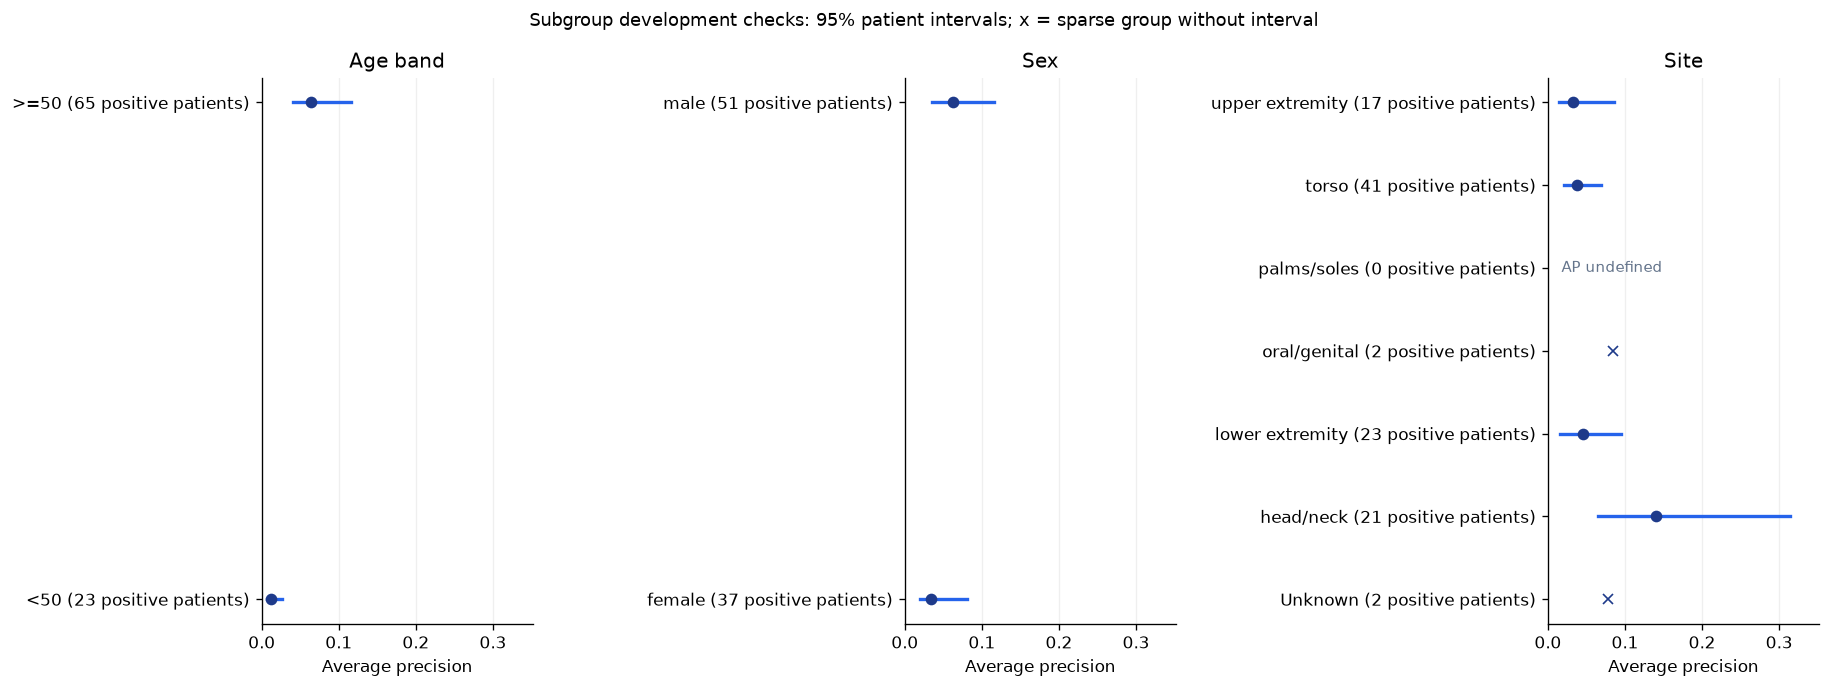

In [7]:
ages = pd.to_numeric(train.age_approx, errors="coerce")
age_groups = pd.Series(np.where(ages.isna(), "Missing", np.where(ages < 50, "<50", ">=50")), index=train.index)
report_groups = {
    "Age band": age_groups,
    "Sex": train.sex.fillna("Missing").astype(str),
    "Site": train.anatom_site_general_challenge.fillna("Missing").astype(str),
}
subgroup_rows = []
for field, labels in report_groups.items():
    for label in sorted(labels.unique()):
        mask = labels.eq(label).to_numpy()
        subset = train.loc[mask].reset_index(drop=True)
        probabilities = outer_predictions.loc[mask, "p_spline_raw"].to_numpy()
        decisions = outer_predictions.loc[mask, "decision_raw"].to_numpy()
        positive_patients = int(subset.groupby("patient_id").target.max().sum())
        row = {"field": field, "group": label, "images": len(subset), "patients": subset.patient_id.nunique(),
               "positive_images": int(subset.target.sum()), "positive_patients": positive_patients,
               "prevalence": subset.target.mean(), **probability_metrics(subset.target, probabilities),
               **decision_metrics(subset.target, decisions),
               "evidence_note": "Sparse: intervals suppressed" if positive_patients < 10 else "Exploratory; no subgroup tuning"}
        for metric in ["average_precision", "roc_auc", "sensitivity"]:
            row[f"{metric}_lower"] = np.nan; row[f"{metric}_upper"] = np.nan
        if positive_patients >= 10 and subset.target.nunique() == 2:
            group_ci = patient_bootstrap(subset.target, subset.patient_id, {"Raw spline": probabilities}, n_bootstrap=1000, seed=42)
            for metric in ["average_precision", "roc_auc"]:
                result = group_ci[group_ci.metric.eq(metric)].iloc[0]
                row[f"{metric}_lower"] = result.ci_lower; row[f"{metric}_upper"] = result.ci_upper
            result = decision_intervals(subset, decisions, repetitions=1000).query("metric == 'sensitivity'").iloc[0]
            row["sensitivity_lower"] = result.ci_lower; row["sensitivity_upper"] = result.ci_upper
        subgroup_rows.append(row)
subgroup_table = pd.DataFrame(subgroup_rows)
subgroup_table.to_csv(TABLES / "metadata_subgroup_checks_d1.csv", index=False)
display(subgroup_table[["field", "group", "images", "patients", "positive_images", "positive_patients", "prevalence", "average_precision", "average_precision_lower", "average_precision_upper", "sensitivity", "evidence_note"]].round(4))

fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.8), sharex=True)
subgroup_maximum = max(subgroup_table.average_precision.max(), subgroup_table.average_precision_upper.max()) * 1.12
for axis, field in zip(axes, report_groups):
    rows = subgroup_table[subgroup_table.field.eq(field)].reset_index(drop=True)
    for index, row in rows.iterrows():
        if pd.notna(row.average_precision_lower):
            axis.plot([row.average_precision_lower, row.average_precision_upper], [index, index], color="#2563EB", linewidth=2)
        axis.plot(row.average_precision, index, "o" if row.positive_patients >= 10 else "x", color="#1E3A8A")
        if pd.isna(row.average_precision):
            axis.text(subgroup_maximum * .05, index, "AP undefined", va="center", fontsize=9, color="#64748B")
    axis.set_yticks(range(len(rows)), [f"{row.group} ({row.positive_patients} positive patients)" for row in rows.itertuples()])
    axis.set_title(field); axis.set_xlabel("Average precision"); axis.set_xlim(0, subgroup_maximum); axis.grid(axis="x", alpha=0.2)
fig.suptitle("Subgroup development checks: 95% patient intervals; x = sparse group without interval", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "metadata_subgroups_d1.png", dpi=180, bbox_inches="tight")
plt.show()

### 8. Fit and save the retained model before final testing

Keep the previously chosen raw four-knot spline, fit it on all development patients and choose its academic cutoff from five-fold development OOF scores. Saving the model together with its cutoff and training identities gives the later test script a complete fixed recipe. The manifest records fingerprints of the model and source files, plus the dependency versions.

The final-test script checks those stored decisions, rejects overlapping patients or images and records one attempted evaluation beside the model bundle. Changing the output directory does not allow another attempt. The script uses the saved cutoff, so test results cannot be used to choose a better-looking one.

This notebook saves the model but does not run the final test. Run the final-test script only after the project's modelling decisions are settled.


In [8]:
if (MODEL_DIR / "frozen_spline.holdout_receipt.json").exists():
    raise RuntimeError("The frozen model has a recorded holdout attempt. Do not refit it after final testing.")
bundle = fit_final_bundle(train, input_sha256=INPUT_HASH, target_recall=TARGET_RECALL)
bundle_path = MODEL_DIR / "frozen_spline.joblib"
joblib.dump(bundle, bundle_path)
versions = {name: importlib.metadata.version(name) for name in ["numpy", "pandas", "scikit-learn", "matplotlib", "joblib", "nbformat", "nbclient"]}
source_paths = [PROJECT_ROOT / "src/melanoma_detection" / name for name in ["metadata_model.py", "metadata_evaluation.py", "metadata_validation.py"]]
source_paths.append(PROJECT_ROOT / "scripts/evaluate_metadata_holdout.py")
manifest = {
    "input_path": str(DATA_PATH.relative_to(PROJECT_ROOT)), "input_sha256": INPUT_HASH,
    "specification": bundle["specification"], "threshold": bundle["threshold"],
    "training_images": len(train), "training_patients": train.patient_id.nunique(),
    "bundle_path": str(bundle_path.relative_to(PROJECT_ROOT)), "bundle_sha256": file_sha256(bundle_path),
    "source_sha256": {str(path.relative_to(PROJECT_ROOT)): file_sha256(path) for path in source_paths},
    "python": platform.python_version(), "versions": versions,
    "bootstrap": {"unit": "patient", "repetitions": BOOTSTRAP_REPETITIONS, "seed": BOOTSTRAP_SEED, "interval": "percentile95", "retraining": False},
    "nn_input_sha256": nn_config["input_sha256"], "nn_prediction_sha256": file_sha256(NN_PATH),
    "status": "fitted on development only; final test not evaluated",
}
bundle_path.with_suffix(".json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
(METRICS / "metadata_robustness_run_config_d1.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Saved:", bundle_path.relative_to(PROJECT_ROOT))
print("Frozen academic cutoff:", round(bundle["threshold"], 6))
print("Reserved test labels were not opened.")

Saved: models\metadata_d1\frozen_spline.joblib
Frozen academic cutoff: 0.0106
Reserved test labels were not opened.


### 9. Check the results together

The printed recap below brings together the AP comparison, its uncertainty interval, the cutoff's detection and review workload, and the number of sparse reporting groups. Read these as development findings for the retained spline.


In [9]:
raw_ap = probability_metrics(train.target, probability_sets["Raw spline"])["average_precision"]
nn_ap = probability_metrics(train.target, probability_sets["NN mean of three"])["average_precision"]
delta = intervals[(intervals.model_name == "NN mean of three") & (intervals.reference_model == "Raw spline") & (intervals.metric == "average_precision")].iloc[0]
raw_decisions = decision_summary.query("procedure == 'Raw spline'").iloc[0]
print(f"Raw spline AP: {raw_ap:.4f}; mean-of-three NN AP: {nn_ap:.4f}.")
print(f"NN minus spline AP: {delta.estimate:+.4f}, patient 95% interval [{delta.ci_lower:+.4f}, {delta.ci_upper:+.4f}].")
print(f"Training-target recall: {TARGET_RECALL:.0%}; held-out raw-spline sensitivity: {raw_decisions.sensitivity:.1%}.")
print(f"At that policy, {raw_decisions.flagged_fraction:.1%} of images are flagged; precision is {raw_decisions.precision:.1%}.")
print(f"Sparse reporting groups: {int(subgroup_table.positive_patients.lt(10).sum())} of {len(subgroup_table)}.")
print("Primary model remains the raw spline. The final test is still closed.")

Raw spline AP: 0.0484; mean-of-three NN AP: 0.0465.
NN minus spline AP: -0.0019, patient 95% interval [-0.0190, +0.0059].
Training-target recall: 80%; held-out raw-spline sensitivity: 79.7%.
At that policy, 67.0% of images are flagged; precision is 2.2%.
Sparse reporting groups: 3 of 11.
Primary model remains the raw spline. The final test is still closed.


## Limitations

These patient folds have already guided earlier model comparisons. Training-only cutoff and calibration selection prevent direct reuse of outer labels for those steps, but they cannot make the earlier model exploration disappear. The selected model still needs the reserved test evaluation.

The bootstrap resamples the saved predictions and decisions without retraining. Its intervals describe patient-sampling uncertainty for those fixed outputs; they do not include the full uncertainty from training, choosing a method or moving to another hospital. Several comparisons are exploratory and their intervals are not adjusted for multiple testing.

Only 128 malignant images are available, and three of the eleven reporting groups have fewer than ten patients with a malignant image. Sparse results cannot establish a reliable group difference. AP also changes with prevalence, so subgroup differences do not establish fairness or causation. Five calibration bins can hide variation within a bin, and their wide intervals do not prove each individual risk estimate is correct.

The 80% recall target is an academic scenario. Finding many malignant images while flagging two-thirds of images does not establish a useful clinical workflow, safety or acceptable costs. The model uses metadata rather than lesion appearance, and all scores remain image-level development results.


## Summary

The raw spline has AP 0.0484 and the three-network mean has AP 0.0465. The network-minus-spline difference is -0.0019, with a patient-bootstrap 95% interval of [-0.0190, +0.0059]. This gives no clear evidence of an AP improvement from the network. Recalibration slightly lowers probability error but also slightly lowers pooled AP and ROC-AUC; it makes the same cutoff decisions in this run.

Retain the raw spline as the primary metadata model and keep the network and recalibration as documented comparisons. The training-selected 80% recall scenario finds 79.7% of malignant images while flagging 67.0% of all images, with 2.2% precision. That workload limits the value of metadata alone. Group results need cautious interpretation, especially the three sparse groups.

The fitted spline and its academic cutoff are saved, and the reserved test has not been used to evaluate these models. Next, finish the project's remaining modelling decisions, keep the saved recipe fixed and run the final-test script once.
